In [2]:
# Cell 1: setup
!pip -q install lightgbm xgboost statsmodels
import numpy as np, pandas as pd, os, time, warnings
warnings.filterwarnings('ignore')
from scipy import stats
from scipy.stats import norm
import matplotlib.pyplot as plt
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, brier_score_loss
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
import torch, torch.nn as nn, torch.nn.functional as Fnn
from sklearn.model_selection import train_test_split
torch.set_num_threads(2)   # CPU is enough for 569 nodes

CSV   = '/content/CANCER_DATA.csv'
N_REP = 10          # 10 x 5 repeated stratified CV, as in the paper
SEED  = 42
K_GRAPH = 7         # k used in the main pipeline (reference model in Sec. 6.6 used k = 10)
TUNE  = True        # same small inner-CV tuning budget for every baseline
OUT   = 'outputs'; os.makedirs(OUT, exist_ok=True)

df   = pd.read_csv(CSV)
y    = (df['diagnosis'] == 'M').astype(int).values          # 1 = malignant, 0 = benign
cols = [c for c in df.columns if c not in ('id', 'diagnosis')]
X    = df[cols].values.astype(float)
print(X.shape, 'malignant:', y.sum(), 'benign:', (1 - y).sum())

(569, 30) malignant: 212 benign: 357


In [3]:
# Cell 2: ONE set of folds for ALL models (#19, #23)
splits = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=N_REP, random_state=SEED).split(X, y))
np.save(f'{OUT}/folds.npy', np.array([(tr, te) for tr, te in splits], dtype=object), allow_pickle=True)
fold_rows = []                 # per-fold metrics of every model
oof = {}                       # oof['model'] has shape (N_REP, n_patients): out-of-fold P(malignant)

def run_model(name, fit_predict):
    # fit_predict(tr, te) -> P(malignant) for patients te, using ONLY patients tr for fitting
    P = np.zeros((N_REP, len(y)))
    t0 = time.time()
    for k, (tr, te) in enumerate(splits):
        p = fit_predict(tr, te)
        P[k // 5, te] = p
        yt = y[te]
        fold_rows.append(dict(model=name, fold=k, rep=k // 5,
                              acc=100 * accuracy_score(yt, p >= .5), f1=100 * f1_score(yt, p >= .5),
                              auc=roc_auc_score(yt, p), brier=brier_score_loss(yt, p)))
    oof[name] = P
    m = pd.DataFrame(fold_rows).query('model == @name')
    print(f'{name:14s} acc {m.acc.mean():.2f} (SD per fold {m.acc.std():.2f})  AUC {m.auc.mean():.4f}  Brier {m.brier.mean():.4f}  [{time.time()-t0:.0f}s]')

In [4]:
# Cell 3: neutrosophic functions (Eqs. 19-25 of the manuscript)
EPS = 1e-8
def fit_gauss(Xtr, ytr, pooled=False):
    a, b = Xtr[ytr == 0], Xtr[ytr == 1]
    mu_b, mu_m = a.mean(0), b.mean(0)
    if pooled:   # same sigma for both classes -> log-likelihood ratio is LINEAR in x -> T is monotone (#6)
        sp = np.sqrt(((len(a)-1)*a.var(0, ddof=1) + (len(b)-1)*b.var(0, ddof=1)) / (len(a)+len(b)-2)) + EPS
        return mu_b, sp, mu_m, sp
    return mu_b, a.std(0) + EPS, mu_m, b.std(0) + EPS

def llr(X_, par):
    mu_b, sd_b, mu_m, sd_m = par                    # l_j = log N(x; benign) - log N(x; malignant)
    return np.clip(norm.logpdf(X_, mu_b, sd_b) - norm.logpdf(X_, mu_m, sd_m), -30, 30)

def tif(L, log_prior_ratio=0.0):
    # T = benign evidence. log_prior_ratio = log(pi_B/pi_M) = log(357/212) = 0.52 for training priors (#5); 0 = equal priors
    T = 1 / (1 + np.exp(-(L + log_prior_ratio)))
    F = 1 - T
    I = 1 - np.abs(2*T - 1)                         # = 2 min(T, F)   (#3)
    return T, I, F

def entropy_weights(T):                              # Eq. 15 with T + F = 1, then w ~ (1 - E)
    E = (1 - 0.5*np.abs(2*T - 1)).mean(0)
    w = 1 - E
    return w / w.sum()

def nwa(T, I, F, w):                                 # neutrosophic weighted aggregation + score S
    Ta = 1 - np.prod((1 - T)**w, 1); Ia = np.prod(I**w, 1); Fa = np.prod(F**w, 1)
    return Ta, Ia, Fa, (2 + Ta - Ia - Fa) / 3

# sanity check for the paper (#3, #4): the 90 values are a function of the 30 LLRs
par = fit_gauss(X, y); T_, I_, F_ = tif(llr(X, par))
print('I == 2 min(T, F):', np.allclose(I_, 2*np.minimum(T_, F_)))

I == 2 min(T, F): True


In [5]:
# Cell 4: reference model with a CLEAR protocol (#16, #17, #18, #24)
# graph built on training patients only (mutual k-NN); each test patient is linked to its k nearest TRAINING patients
# (inductive: no test-test edges, no test labels). Isolated nodes keep their own features (self-loop).
def mutual_knn(Z, k):
    idx = NearestNeighbors(n_neighbors=k + 1).fit(Z).kneighbors(Z, return_distance=False)[:, 1:]
    A = np.zeros((len(Z), len(Z)), bool)
    for i in range(len(Z)): A[i, idx[i]] = True
    return A & A.T

def ref_features(tr, te, k=10, pooled=False, prior_shift=0.0):
    sc = StandardScaler().fit(X[tr]); Ztr, Zte = sc.transform(X[tr]), sc.transform(X[te])
    par = fit_gauss(Ztr, y[tr], pooled)
    Ttr, Itr, Ftr = tif(llr(Ztr, par), prior_shift); Tte, Ite, Fte = tif(llr(Zte, par), prior_shift)
    w = entropy_weights(Ttr)
    _, _, _, Str = nwa(Ttr, Itr, Ftr, w); _, Iag, _, Ste = nwa(Tte, Ite, Fte, w)
    Btr = np.c_[Str, Ztr]; Bte = np.c_[Ste, Zte]           # node features: [S_i, standardised features]
    A = mutual_knn(Ztr, k); deg = A.sum(1, keepdims=True)
    Mtr = np.where(deg > 0, (A.astype(float) @ Btr) / np.maximum(deg, 1), Btr)   # isolated -> self
    nbr = NearestNeighbors(n_neighbors=k).fit(Ztr).kneighbors(Zte, return_distance=False)
    Mte = Btr[nbr].mean(1)
    return np.c_[Btr, Mtr], np.c_[Bte, Mte], Iag            # one propagation step: [own, neighbour mean]

def ref_fit_predict(tr, te, **kw):
    Htr, Hte, _ = ref_features(tr, te, **kw)
    return LogisticRegression(C=1, max_iter=5000).fit(Htr, y[tr]).predict_proba(Hte)[:, 1]

# I_agg of every test patient (needed in cell 10)
Iagg = np.zeros((N_REP, len(y)))
for k, (tr, te) in enumerate(splits):
    Iagg[k // 5, te] = ref_features(tr, te, k=10)[2]
run_model('RefNGNN-MADM', lambda tr, te: ref_fit_predict(tr, te, k=10))

RefNGNN-MADM   acc 97.47 (SD per fold 1.51)  AUC 0.9938  Brier 0.0211  [3s]


In [6]:
# Cell 5: baselines, SAME folds, scaler inside the fold, SAME tuning budget (3-fold inner CV on the training fold) (#23)
def tuned(est, grid):
    pipe = Pipeline([('sc', StandardScaler()), ('m', est)])
    if not TUNE: return pipe
    return GridSearchCV(pipe, {'m__' + k: v for k, v in grid.items()}, cv=3, scoring='neg_log_loss', n_jobs=-1)

MODELS = {
  'LR':       lambda: tuned(LogisticRegression(max_iter=5000), {'C': [0.1, 1, 10]}),
  'SVM':      lambda: tuned(SVC(probability=True, random_state=0), {'C': [1, 10], 'gamma': [0.01, 0.03]}),
  'RF':       lambda: tuned(RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1), {'max_depth': [5, 10, None]}),
  'MLP':      lambda: tuned(MLPClassifier((64, 32), max_iter=2000, random_state=0), {'alpha': [1e-4, 1e-2]}),
  'LightGBM': lambda: tuned(LGBMClassifier(n_estimators=300, learning_rate=0.05, verbose=-1, random_state=0), {'num_leaves': [7, 15]}),
  'XGBoost':  lambda: tuned(XGBClassifier(n_estimators=300, learning_rate=0.1, eval_metric='logloss', random_state=0, n_jobs=-1), {'max_depth': [3, 5]}),
}
for name, make in MODELS.items():
    run_model(name, lambda tr, te, make=make: make().fit(X[tr], y[tr]).predict_proba(X[te])[:, 1])
# CatBoost, SAINT, FT-Transformer, TabNet, GCN, GAT, ... : run them with YOUR existing code through run_model(name, fit_predict)

LR             acc 97.89 (SD per fold 1.43)  AUC 0.9948  Brier 0.0200  [9s]
SVM            acc 97.56 (SD per fold 1.36)  AUC 0.9956  Brier 0.0191  [11s]
RF             acc 95.69 (SD per fold 1.96)  AUC 0.9896  Brier 0.0330  [235s]
MLP            acc 97.70 (SD per fold 1.35)  AUC 0.9936  Brier 0.0201  [95s]
LightGBM       acc 96.66 (SD per fold 1.31)  AUC 0.9933  Brier 0.0277  [53s]
XGBoost        acc 96.52 (SD per fold 1.77)  AUC 0.9933  Brier 0.0255  [59s]


In [7]:
# Cell 6a: NGNN-MADM, revised (PyTorch, CPU). Answers #16, #17, #18.
HID, LAYERS, DROP, LR_, WD, LAMBDA, EPOCHS, PATIENCE = 32, 2, 0.3, 1e-2, 1e-3, 0.1, 300, 30   # write THESE values in the paper

def build_fold(tr, te, k=K_GRAPH, pooled=False, weights='entropy', prior=False, ablate_agg=False):
    """Everything below is fitted on the TRAINING fold only."""
    sc = StandardScaler().fit(X[tr]); Ztr, Zte = sc.transform(X[tr]), sc.transform(X[te])
    par = fit_gauss(Ztr, y[tr], pooled)
    shift = np.log((y[tr] == 0).mean() / (y[tr] == 1).mean()) if prior else 0.0
    Ttr, Itr, Ftr = tif(llr(Ztr, par), shift); Tte, Ite, Fte = tif(llr(Zte, par), shift)
    w = entropy_weights(Ttr) if weights == 'entropy' else np.ones(Ztr.shape[1]) / Ztr.shape[1]
    A_tr = nwa(Ttr, Itr, Ftr, w); A_te = nwa(Tte, Ite, Fte, w)          # (T_agg, I_agg, F_agg, S)
    Ta, Ia, Fa, S = [np.r_[a, b] for a, b in zip(A_tr, A_te)]
    if ablate_agg: Ta, Ia, Fa, S = [np.zeros_like(v) for v in (Ta, Ia, Fa, S)]
    T, I, F, Z = np.r_[Ttr, Tte], np.r_[Itr, Ite], np.r_[Ftr, Fte], np.r_[Ztr, Zte]
    blocks = {'T': np.c_[T, Ta], 'I': np.c_[I, Ia], 'F': np.c_[F, Fa], 'S': S[:, None], 'X': Z}
    # graph: mutual k-NN among TRAINING patients, Gaussian-kernel weights
    ntr, nte = len(tr), len(te)
    nbrs = NearestNeighbors(n_neighbors=k + 1).fit(Ztr); _, idx = nbrs.kneighbors(Ztr)
    B = np.zeros((ntr, ntr), bool); B[np.repeat(np.arange(ntr), k), idx[:, 1:].ravel()] = True
    M = B & B.T
    D = np.sqrt(((Ztr[:, None, :] - Ztr[None, :, :]) ** 2).sum(2))
    sigma = np.median(D[M & (D > 0)])
    A = np.zeros((ntr + nte, ntr + nte)); A[:ntr, :ntr] = np.where(M, np.exp(-D ** 2 / (2 * sigma ** 2)), 0.0)
    d2, idx2 = nbrs.kneighbors(Zte, n_neighbors=k)            # each TEST patient -> its k nearest TRAINING patients (one-directional)
    for r in range(nte): A[ntr + r, idx2[r]] = np.exp(-d2[r] ** 2 / (2 * sigma ** 2))
    deg = A.sum(1, keepdims=True); Ahat = A / np.maximum(deg, 1e-12)   # isolated node: message 0, it keeps its own state (self term)
    return dict(blocks=blocks, Ahat=Ahat, ntr=ntr, Iagg_te=Ia[ntr:])

def to_t(a): return torch.tensor(np.asarray(a), dtype=torch.float32)

class NGNN(nn.Module):
    """Three channels. Channel T reads ONLY the 30 T-values (+ T_agg), channel I only the 30 I-values (+ I_agg),
    channel F only the 30 F-values (+ F_agg). S_i enters at the classifier. Output = ONE logit (P(malignant)).
    T_final, I_final, F_final are bounded scalars (sigmoid of a linear read-out of each channel)."""
    def __init__(s, d=30, hid=HID, layers=LAYERS, drop=DROP, use_I=True, use_graph=True):
        super().__init__()
        s.chans = ['T', 'I', 'F'] if use_I else ['T', 'F']; s.layers, s.use_graph = layers, use_graph
        s.inp = nn.ModuleDict({c: nn.Linear(d + 1, hid) for c in s.chans})
        s.selfw = nn.ModuleList([nn.ModuleDict({c: nn.Linear(hid, hid) for c in s.chans}) for _ in range(layers)])
        s.nbrw = nn.ModuleList([nn.ModuleDict({c: nn.Linear(hid, hid, bias=False) for c in s.chans}) for _ in range(layers)])
        s.read = nn.ModuleDict({c: nn.Linear(hid, 1) for c in s.chans})
        s.cls = nn.Sequential(nn.Linear(hid * len(s.chans) + 1, 32), nn.ReLU(), nn.Dropout(drop), nn.Linear(32, 1))
        s.drop = nn.Dropout(drop)
    def forward(s, B, Ahat):
        h = {c: torch.relu(s.inp[c](B[c])) for c in s.chans}
        for l in range(s.layers):
            new = {}
            for c in s.chans:
                z = s.selfw[l][c](h[c])
                if s.use_graph: z = z + s.nbrw[l][c](Ahat @ h[c])
                new[c] = s.drop(torch.relu(z)) + h[c]                  # residual
            h = new
        logit = s.cls(torch.cat([h[c] for c in s.chans] + [B['S']], 1)).squeeze(1)
        return logit, {c: torch.sigmoid(s.read[c](h[c])).squeeze(1) for c in s.chans}

class GNNBase(nn.Module):
    """Graph baselines on the standardised features only: 'gcn' (mean over neighbours and itself) or 'sage' (GraphSAGE-mean)."""
    def __init__(s, d=30, hid=HID, kind='gcn', layers=LAYERS, drop=DROP):
        super().__init__(); s.kind, s.layers = kind, layers
        s.inp = nn.Linear(d, hid); s.W = nn.ModuleList([nn.Linear(hid, hid) for _ in range(layers)])
        s.Wn = nn.ModuleList([nn.Linear(hid, hid, bias=False) for _ in range(layers)])
        s.out = nn.Linear(hid, 1); s.drop = nn.Dropout(drop)
    def forward(s, B, Ahat):
        h = torch.relu(s.inp(B['X']))
        for l in range(s.layers):
            m = Ahat @ h
            z = s.W[l]((h + m) / 2) if s.kind == 'gcn' else s.W[l](h) + s.Wn[l](m)
            h = s.drop(torch.relu(z))
        return s.out(h).squeeze(1), {}

def fit_graph_model(tr, te, make, lam=LAMBDA, build_kw=None, seed=None):
    seed = int(te[:5].sum()) % 100000 if seed is None else seed
    f = build_fold(tr, te, **(build_kw or {}))
    B = {k_: to_t(v) for k_, v in f['blocks'].items()}; A = to_t(f['Ahat']); ntr = f['ntr']; yt = to_t(y[tr])
    torch.manual_seed(seed); np.random.seed(seed)
    model = make(); opt = torch.optim.Adam(model.parameters(), lr=LR_, weight_decay=WD)
    fit_i, val_i = train_test_split(np.arange(ntr), test_size=0.2, stratify=y[tr], random_state=seed)   # early stopping INSIDE the training fold
    fit_i, val_i = torch.tensor(fit_i), torch.tensor(val_i)
    best, best_state, bad = 1e9, None, 0
    for ep in range(EPOCHS):
        model.train(); opt.zero_grad()
        logit, scal = model(B, A)
        loss = Fnn.binary_cross_entropy_with_logits(logit[fit_i], yt[fit_i])
        if lam > 0 and 'I' in scal:                                    # bounded I_final, target 1-|2p-1| in [0,1], stop-gradient on p
            tgt = 1 - (2 * torch.sigmoid(logit.detach()) - 1).abs()
            loss = loss + lam * ((scal['I'][fit_i] - tgt[fit_i]) ** 2).mean()
        loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            lg, _ = model(B, A); vl = Fnn.binary_cross_entropy_with_logits(lg[val_i], yt[val_i]).item()
        if vl < best - 1e-4:
            best, bad = vl, 0; best_state = {k_: v.clone() for k_, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(best_state); model.eval()
    with torch.no_grad(): lg, scal = model(B, A)
    return dict(model=model, B=B, A=A, ntr=ntr, p=torch.sigmoid(lg)[ntr:].numpy(),
                scal={c: v[ntr:].numpy() for c, v in scal.items()}, Iagg=f['Iagg_te'])

def mc_dropout(m, passes=30):
    m['model'].train()
    with torch.no_grad():
        P = torch.stack([torch.sigmoid(m['model'](m['B'], m['A'])[0])[m['ntr']:] for _ in range(passes)]).numpy()
    m['model'].eval(); return P.mean(0), P.std(0)
print('NGNN parameters:', sum(p.numel() for p in NGNN().parameters()), '| device: CPU')

NGNN parameters: 18820 | device: CPU


In [8]:
# Cell 6b: run the full NGNN-MADM and the graph baselines on the SAME folds
FIN = {c: np.full((N_REP, len(y)), np.nan) for c in 'TIF'}; _calls = {'k': 0}
def ngnn_main(tr, te):
    m = fit_graph_model(tr, te, lambda: NGNN(), lam=LAMBDA)
    rep = _calls['k'] // 5; _calls['k'] += 1
    for c in 'TIF': FIN[c][rep, te] = m['scal'][c]                 # saved for the heatmap (cell 15)
    return m['p']
run_model('NGNN-MADM', ngnn_main)
run_model('GCN',       lambda tr, te: fit_graph_model(tr, te, lambda: GNNBase(kind='gcn'),  lam=0.0)['p'])
run_model('GraphSAGE', lambda tr, te: fit_graph_model(tr, te, lambda: GNNBase(kind='sage'), lam=0.0)['p'])

NGNN-MADM      acc 96.47 (SD per fold 2.00)  AUC 0.9943  Brier 0.0261  [137s]
GCN            acc 95.83 (SD per fold 2.25)  AUC 0.9887  Brier 0.0329  [28s]
GraphSAGE      acc 96.31 (SD per fold 2.48)  AUC 0.9898  Brier 0.0305  [28s]


In [10]:
# Cell 6c: ablations and sensitivity (#29, #12, #5, #6). Paired tests against the full model.
VARIANTS = {
 'A1 equal weights':        dict(make=lambda: NGNN(), bk=dict(weights='equal')),
 'A2 no A_i, S_i':          dict(make=lambda: NGNN(), bk=dict(ablate_agg=True)),
 'A3 no graph (MLP)':       dict(make=lambda: NGNN(use_graph=False)),
 'A4 no I channel':         dict(make=lambda: NGNN(use_I=False)),
 'A4b no I, wider net':     dict(make=lambda: NGNN(use_I=False, hid=40)),      # capacity control
 'A5 no uncertainty loss':  dict(make=lambda: NGNN(), lam=0.0),
 'pooled variance (T monotone)': dict(make=lambda: NGNN(), bk=dict(pooled=True)),
 'training-fold priors':    dict(make=lambda: NGNN(), bk=dict(prior=True)),
 'k = 5':                   dict(make=lambda: NGNN(), bk=dict(k=5)),
 'k = 10':                  dict(make=lambda: NGNN(), bk=dict(k=10)),
}
for name, v in VARIANTS.items():
    run_model(name, lambda tr, te, v=v: fit_graph_model(tr, te, v['make'], lam=v.get('lam', LAMBDA), build_kw=v.get('bk'))['p'])
fd = pd.DataFrame(fold_rows); pv = fd.pivot(index='fold', columns='model', values='acc'); out = []
for name in VARIANTS:
    d = pv[name] - pv['NGNN-MADM']; t = d.mean() / (d.std(ddof=1) * np.sqrt(1/len(splits) + 0.25)) if d.std() > 0 else 0
    out.append(dict(variant=name, acc=pv[name].mean(), diff_vs_full=d.mean(), SD_d=d.std(ddof=1), p_NB=2 * stats.t.sf(abs(t), len(splits) - 1)))
ab = pd.DataFrame(out); o = ab.p_NB.argsort().values; adj = np.zeros(len(ab)); run = 0
for r, i in enumerate(o): run = max(run, (len(ab) - r) * ab.p_NB[i]); adj[i] = min(1, run)
ab['p_Holm'] = adj; print(ab.round(3)); ab.round(4).to_csv(f'{OUT}/ablation_paired_tests.csv', index=False)

A1 equal weights acc 96.68 (SD per fold 1.79)  AUC 0.9942  Brier 0.0256  [106s]
A2 no A_i, S_i acc 96.54 (SD per fold 2.02)  AUC 0.9941  Brier 0.0256  [104s]
A3 no graph (MLP) acc 96.91 (SD per fold 1.54)  AUC 0.9945  Brier 0.0251  [57s]
A4 no I channel acc 96.33 (SD per fold 2.10)  AUC 0.9937  Brier 0.0269  [70s]
A4b no I, wider net acc 96.54 (SD per fold 1.99)  AUC 0.9943  Brier 0.0271  [83s]
A5 no uncertainty loss acc 96.66 (SD per fold 1.89)  AUC 0.9942  Brier 0.0259  [95s]
pooled variance (T monotone) acc 96.93 (SD per fold 1.87)  AUC 0.9934  Brier 0.0246  [102s]
training-fold priors acc 96.31 (SD per fold 1.97)  AUC 0.9938  Brier 0.0283  [93s]
k = 5          acc 96.52 (SD per fold 1.64)  AUC 0.9943  Brier 0.0266  [98s]
k = 10         acc 96.52 (SD per fold 1.67)  AUC 0.9938  Brier 0.0269  [104s]
                        variant     acc  diff_vs_full   SD_d   p_NB  p_Holm
0              A1 equal weights  96.679         0.211  0.981  0.682     1.0
1                A2 no A_i, S_i  96

In [9]:
# FIX: remove duplicate rows (keep the latest run) and make run_model safe to re-run
fold_rows = pd.DataFrame(fold_rows).drop_duplicates(subset=['model', 'fold'], keep='last').to_dict('records')
print(pd.DataFrame(fold_rows).groupby('model').size())      # every model must show 50

def run_model(name, fit_predict):
    global fold_rows
    fold_rows = [r for r in fold_rows if r['model'] != name]   # re-running a model replaces its old rows
    P = np.zeros((N_REP, len(y))); t0 = time.time()
    for k, (tr, te) in enumerate(splits):
        p = fit_predict(tr, te); P[k // 5, te] = p; yt = y[te]
        fold_rows.append(dict(model=name, fold=k, rep=k // 5, acc=100 * accuracy_score(yt, p >= .5), f1=100 * f1_score(yt, p >= .5),
                              auc=roc_auc_score(yt, p), brier=brier_score_loss(yt, p)))
    oof[name] = P
    m = pd.DataFrame(fold_rows).query('model == @name')
    print(f'{name:14s} acc {m.acc.mean():.2f} (SD per fold {m.acc.std():.2f})  AUC {m.auc.mean():.4f}  Brier {m.brier.mean():.4f}  [{time.time()-t0:.0f}s]')

# second half of Cell 6c (paired tests vs the full model)
fd = pd.DataFrame(fold_rows); pv = fd.pivot(index='fold', columns='model', values='acc'); out = []
for name in VARIANTS:
    d = pv[name] - pv['NGNN-MADM']; t = d.mean() / (d.std(ddof=1) * np.sqrt(1/len(splits) + 0.25)) if d.std() > 0 else 0
    out.append(dict(variant=name, acc=pv[name].mean(), diff_vs_full=d.mean(), SD_d=d.std(ddof=1), p_NB=2 * stats.t.sf(abs(t), len(splits) - 1)))
ab = pd.DataFrame(out); o = ab.p_NB.argsort().values; adj = np.zeros(len(ab)); run = 0
for r, i in enumerate(o): run = max(run, (len(ab) - r) * ab.p_NB[i]); adj[i] = min(1, run)
ab['p_Holm'] = adj; print(ab.round(3)); ab.round(4).to_csv(f'{OUT}/ablation_paired_tests.csv', index=False)

model
GCN             50
GraphSAGE       50
LR              50
LightGBM        50
MLP             50
NGNN-MADM       50
RF              50
RefNGNN-MADM    50
SVM             50
XGBoost         50
dtype: int64


NameError: name 'VARIANTS' is not defined

In [11]:
# Cell 7: Table 1 and Table 2 recomputed from per-fold values (#20, #21, #22)
fold_df = pd.DataFrame(fold_rows); fold_df.to_csv(f'{OUT}/per_fold_metrics.csv', index=False)
MAIN = [m for m in ['LR','SVM','RF','MLP','LightGBM','XGBoost','GCN','GraphSAGE','NGNN-MADM','RefNGNN-MADM'] if m in oof]
fd_all = fold_df; fold_df = fold_df[fold_df.model.isin(MAIN)]   # Table 1/2 = main models only
kr, ratio = len(splits), 0.25                     # n_test / n_train = 1/4 in 5-fold CV
tcrit = stats.t.ppf(0.975, kr - 1)
rows = []
for m, g in fold_df.groupby('model'):
    sd = g.acc.std(ddof=1); half = tcrit * sd * np.sqrt(1/kr + ratio)
    rows.append(dict(model=m, acc=g.acc.mean(), SD_per_fold=sd, CI_low=g.acc.mean() - half, CI_high=g.acc.mean() + half,
                     F1=g.f1.mean(), AUC=g.auc.mean(), Brier=g.brier.mean()))
table1 = pd.DataFrame(rows).sort_values('acc', ascending=False).round(3); table1.to_csv(f'{OUT}/table1.csv', index=False); print(table1)

TARGET = 'NGNN-MADM' if 'NGNN-MADM' in oof else 'RefNGNN-MADM'
piv = fold_df.pivot(index='fold', columns='model', values='acc')
res = []
for m in piv.columns.drop(TARGET):
    d = piv[TARGET] - piv[m]; sd_d = d.std(ddof=1)
    t = d.mean() / (sd_d * np.sqrt(1/kr + ratio)) if sd_d > 0 else 0.0
    res.append(dict(vs=m, mean_diff=d.mean(), SD_d=sd_d, dz=d.mean() / sd_d if sd_d > 0 else 0.0, t_NB=t, p_raw=2 * stats.t.sf(abs(t), kr - 1)))
res = pd.DataFrame(res); o = res.p_raw.argsort().values; adj = np.zeros(len(res)); run = 0
for r, i in enumerate(o): run = max(run, (len(res) - r) * res.p_raw[i]); adj[i] = min(1, run)
res['p_Holm'] = adj; table2 = res.round(4); table2.to_csv(f'{OUT}/table2.csv', index=False)
print('\nTable 2 (target =', TARGET, ')'); print(table2)
print('\nCheck (#21): SD of a paired difference can never exceed SD_a + SD_b ->',
      all(table2.SD_d.values <= (fold_df.groupby('model').acc.std().loc[TARGET] + fold_df.groupby('model').acc.std().loc[table2.vs].values) + 1e-9))

          model     acc  SD_per_fold  CI_low  CI_high      F1    AUC  Brier
2            LR  97.891        1.431  96.397   99.386  97.105  0.995  0.020
4           MLP  97.698        1.351  96.287   99.109  96.854  0.994  0.020
8           SVM  97.558        1.355  96.142   98.973  96.690  0.996  0.019
7  RefNGNN-MADM  97.469        1.514  95.889   99.050  96.494  0.994  0.021
3      LightGBM  96.660        1.305  95.297   98.023  95.430  0.993  0.028
9       XGBoost  96.519        1.771  94.670   98.368  95.244  0.993  0.026
5     NGNN-MADM  96.468        1.996  94.384   98.552  95.162  0.994  0.026
1     GraphSAGE  96.310        2.484  93.716   98.904  94.862  0.990  0.031
0           GCN  95.833        2.255  93.479   98.188  94.225  0.989  0.033
6            RF  95.694        1.964  93.643   97.744  94.129  0.990  0.033

Table 2 (target = NGNN-MADM )
             vs  mean_diff    SD_d      dz    t_NB   p_raw  p_Holm
0           GCN     0.6348  1.7408  0.3647  0.7018  0.4861     1.0

In [12]:
# Cell 8: calibration, DeLong, McNemar (#24). Uses repetition 0 (one out-of-fold prediction per patient)
def delong_p(y_true, p1, p2):
    # Sun & Xu (2014) fast DeLong test for two correlated AUCs
    def midrank(x):
        o = np.argsort(x); z = x[o]; n = len(x); r = np.zeros(n); i = 0
        while i < n:
            j = i
            while j < n and z[j] == z[i]: j += 1
            r[i:j] = 0.5 * (i + j - 1) + 1; i = j
        out = np.empty(n); out[o] = r; return out
    pos = y_true == 1; m, n = pos.sum(), (~pos).sum(); V10, V01, aucs = [], [], []
    for p in (p1, p2):
        tx, ty = midrank(p[pos]), midrank(p[~pos]); tz = midrank(p)
        aucs.append((tz[pos].sum() - m*(m+1)/2) / (m*n)); V10.append((tz[pos] - tx) / n); V01.append(1 - (tz[~pos] - ty) / m)
    S10, S01 = np.cov(np.array(V10)), np.cov(np.array(V01)); S = S10/m + S01/n
    var = S[0,0] + S[1,1] - 2*S[0,1]
    z = (aucs[0] - aucs[1]) / np.sqrt(var) if var > 0 else 0.0
    return aucs[0], aucs[1], 2 * stats.norm.sf(abs(z))

def mcnemar_exact(y_true, p1, p2):
    c1, c2 = (p1 >= .5) == y_true, (p2 >= .5) == y_true
    b, c = int((c1 & ~c2).sum()), int((~c1 & c2).sum())
    return b, c, (1.0 if b + c == 0 else min(1.0, 2 * stats.binom.cdf(min(b, c), b + c, .5)))

def calib(p):
    ece = 0.0; bins = np.linspace(0, 1, 11)
    for lo, hi in zip(bins[:-1], bins[1:]):
        s = (p >= lo) & (p < hi + (hi == 1))
        if s.any(): ece += s.mean() * abs(y[s].mean() - p[s].mean())
    lg = np.log(np.clip(p, 1e-6, 1-1e-6) / (1 - np.clip(p, 1e-6, 1-1e-6)))
    cs = LogisticRegression(C=1e6, max_iter=1000).fit(lg[:, None], y)
    return dict(Brier=brier_score_loss(y, p), ECE=ece, slope=cs.coef_[0, 0], intercept=cs.intercept_[0])
print(pd.DataFrame({m: calib(oof[m][0]) for m in MAIN}).T.round(4))
for other in [m for m in MAIN if m != TARGET]:
    a1, a2, p = delong_p(y, oof[TARGET][0], oof[other][0]); b, c, pm = mcnemar_exact(y, oof[TARGET][0], oof[other][0])
    print(f'{TARGET} vs {other:12s} AUC {a1:.4f} vs {a2:.4f}  DeLong p={p:.3f} | McNemar b={b} c={c} exact p={pm:.4f}')

               Brier     ECE   slope  intercept
LR            0.0200  0.0151  1.1578     0.2510
SVM           0.0195  0.0140  1.1918     0.1074
RF            0.0333  0.0297  1.1767     0.0455
MLP           0.0192  0.0189  0.5193     0.0170
LightGBM      0.0300  0.0322  0.4160     0.2486
XGBoost       0.0267  0.0130  0.7884     0.1339
GCN           0.0377  0.0311  0.6345     0.3214
GraphSAGE     0.0380  0.0278  0.6965     0.3791
NGNN-MADM     0.0283  0.0245  0.6981    -0.0950
RefNGNN-MADM  0.0205  0.0232  1.0569     0.4380
NGNN-MADM vs LR           AUC 0.9914 vs 0.9947  DeLong p=0.133 | McNemar b=5 c=14 exact p=0.0636
NGNN-MADM vs SVM          AUC 0.9914 vs 0.9949  DeLong p=0.087 | McNemar b=3 c=15 exact p=0.0075
NGNN-MADM vs RF           AUC 0.9914 vs 0.9879  DeLong p=0.401 | McNemar b=10 c=9 exact p=1.0000
NGNN-MADM vs MLP          AUC 0.9914 vs 0.9942  DeLong p=0.223 | McNemar b=4 c=17 exact p=0.0072
NGNN-MADM vs LightGBM     AUC 0.9914 vs 0.9920  DeLong p=0.798 | McNemar b=8 c=13 ex

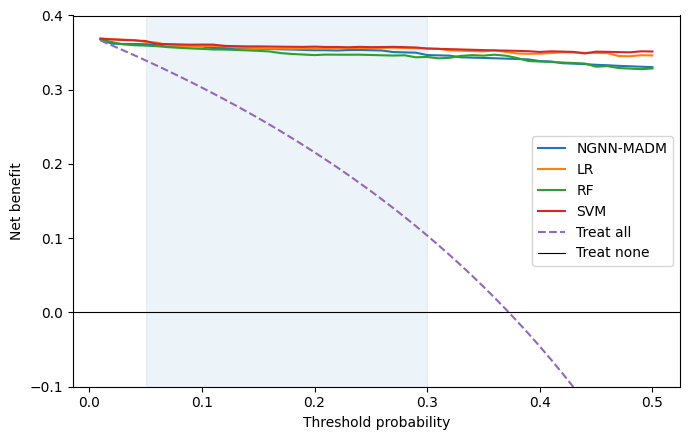

In [13]:
# Cell 9: full decision curve (#25)
pts = np.linspace(0.01, 0.5, 50); N = len(y); prev = y.mean()
def nb(p, t):
    pred = p >= t; return (pred & (y == 1)).sum()/N - (pred & (y == 0)).sum()/N * t/(1 - t)
plt.figure(figsize=(7, 4.5))
for m in [TARGET, 'LR', 'RF', 'SVM']:
    if m in oof: plt.plot(pts, [nb(oof[m][0], t) for t in pts], label=m)
plt.plot(pts, [prev - (1 - prev)*t/(1 - t) for t in pts], '--', label='Treat all')
plt.axhline(0, color='k', lw=.8, label='Treat none'); plt.axvspan(0.05, 0.3, alpha=.08, color='C0')
plt.ylim(-0.1, 0.4); plt.xlabel('Threshold probability'); plt.ylabel('Net benefit'); plt.legend(); plt.tight_layout()
plt.savefig(f'{OUT}/decision_curve.png', dpi=200); plt.show()

In [14]:
# Cell 10: does I_agg add information beyond model confidence? (#26) - uses the TARGET model (full NGNN-MADM)
from sklearn.metrics import roc_auc_score
import statsmodels.api as sm
rows = []
for r in range(N_REP):
    p = oof[TARGET][r]; err = ((p >= .5) != y).astype(int); conf = np.maximum(p, 1 - p)
    if err.sum() < 2: continue
    Z = np.c_[1 - conf, Iagg[r]]
    both = cross_val_predict(LogisticRegression(max_iter=1000), Z, err, cv=StratifiedKFold(5, shuffle=True, random_state=r), method='predict_proba')[:, 1]
    rows.append(dict(rep=r, errors=err.sum(), AUROC_Iagg=roc_auc_score(err, Iagg[r]), AUROC_1_minus_conf=roc_auc_score(err, 1 - conf), AUROC_both=roc_auc_score(err, both)))
err_df = pd.DataFrame(rows); print(err_df.round(3)); print(err_df.mean().round(3))
p = oof[TARGET][0]; err = ((p >= .5) != y).astype(int); conf = np.maximum(p, 1 - p)
m0 = sm.Logit(err, sm.add_constant(1 - conf)).fit(disp=0); m1 = sm.Logit(err, sm.add_constant(np.c_[1 - conf, Iagg[0]])).fit(disp=0)
print('Likelihood-ratio test, adding I_agg to confidence: p =', stats.chi2.sf(2*(m1.llf - m0.llf), 1))
print('\nErrors inside confidence strata, split by I_agg >= 0.5:')
for lo, hi in [(.5, .7), (.7, .9), (.9, 1.01)]:
    s = (conf >= lo) & (conf < hi)
    print(f'conf [{lo},{hi}) n={s.sum():3d} | errors with I_agg>=.5: {err[s & (Iagg[0] >= .5)].sum()}/{(s & (Iagg[0] >= .5)).sum()} | with I_agg<.5: {err[s & (Iagg[0] < .5)].sum()}/{(s & (Iagg[0] < .5)).sum()}')
err_df.to_csv(f'{OUT}/iagg_vs_confidence.csv', index=False)

   rep  errors  AUROC_Iagg  AUROC_1_minus_conf  AUROC_both
0    0      24       0.756               0.947       0.885
1    1      16       0.798               0.935       0.855
2    2      14       0.758               0.928       0.805
3    3      17       0.742               0.941       0.878
4    4      22       0.800               0.909       0.882
5    5      19       0.774               0.901       0.808
6    6      24       0.824               0.877       0.855
7    7      19       0.764               0.827       0.823
8    8      21       0.783               0.933       0.898
9    9      25       0.776               0.909       0.902
rep                    4.500
errors                20.100
AUROC_Iagg             0.777
AUROC_1_minus_conf     0.911
AUROC_both             0.859
dtype: float64
Likelihood-ratio test, adding I_agg to confidence: p = 0.053879324100550956

Errors inside confidence strata, split by I_agg >= 0.5:
conf [0.5,0.7) n=  9 | errors with I_agg>=.5: 4/4 | with I

In [15]:
# Cell 11: standard uncertainty baselines (#28): 5-seed ensemble and split-conformal prediction (repetition 0)
rep0 = splits[:5]; ens_unc = np.zeros(len(y)); ens_p = np.zeros(len(y)); conf_rows = []
for tr, te in rep0:
    Htr, Hte, _ = ref_features(tr, te, k=10); P = []
    for s in range(5):                                           # 5 differently seeded MLP heads on the same inputs
        P.append(MLPClassifier((32,), max_iter=2000, random_state=s).fit(Htr, y[tr]).predict_proba(Hte)[:, 1])
    P = np.array(P); ens_p[te] = P.mean(0); ens_unc[te] = P.std(0)
    # split-conformal (LAC): hold out 25% of the training fold for calibration
    a, b = next(StratifiedKFold(4, shuffle=True, random_state=0).split(Htr, y[tr]))
    lr = LogisticRegression(max_iter=5000).fit(Htr[a], y[tr][a]); pc = lr.predict_proba(Htr[b])[:, 1]
    cal = 1 - np.where(y[tr][b] == 1, pc, 1 - pc); pt = lr.predict_proba(Hte)[:, 1]
    for alpha in (0.10, 0.05):
        q = np.quantile(cal, min(1, np.ceil((len(cal) + 1) * (1 - alpha)) / len(cal)))
        in0, in1 = pt <= q, (1 - pt) <= q                               # label 0 kept if p <= q ; label 1 kept if 1-p <= q
        size = in0.astype(int) + in1.astype(int); covered = np.where(y[te] == 1, in1, in0)
        conf_rows += [dict(alpha=alpha, covered=c, size=s_) for c, s_ in zip(covered, size)]
err = ((ens_p >= .5) != y).astype(int); conf = np.maximum(ens_p, 1 - ens_p)
print('Error-detection AUROC | I_agg:', round(roc_auc_score(err, Iagg[0]), 3), '| 1-confidence:', round(roc_auc_score(err, 1 - conf), 3),
      '| ensemble SD:', round(roc_auc_score(err, ens_unc), 3))
cdf = pd.DataFrame(conf_rows); print(cdf.groupby('alpha').agg(coverage=('covered', 'mean'), mean_set_size=('size', 'mean'), frac_not_singleton=('size', lambda s: (s != 1).mean())).round(3))

Error-detection AUROC | I_agg: 0.757 | 1-confidence: 0.928 | ensemble SD: 0.922
       coverage  mean_set_size  frac_not_singleton
alpha                                             
0.05      0.949          0.965               0.039
0.10      0.902          0.909               0.091


In [16]:
# Cell 11b: uncertainty of the FULL NGNN-MADM: deep ensemble (5 seeds) and MC dropout (30 passes) versus I_final / I_agg (#28), repetition 0
n = len(y); ens_p = np.zeros(n); ens_sd = np.zeros(n); mc_p = np.zeros(n); mc_sd = np.zeros(n)
for tr, te in splits[:5]:
    P = []
    for s in range(5):
        m = fit_graph_model(tr, te, lambda: NGNN(), lam=LAMBDA, seed=1000 + s); P.append(m['p'])
        if s == 0: mc_p[te], mc_sd[te] = mc_dropout(m, 30)
    P = np.array(P); ens_p[te], ens_sd[te] = P.mean(0), P.std(0)
err = ((oof['NGNN-MADM'][0] >= .5) != y).astype(int)
print('errors:', err.sum())
scores = {'I_final (learned)': FIN['I'][0], 'I_agg (data level)': Iagg[0], '1 - confidence': 1 - np.maximum(oof['NGNN-MADM'][0], 1 - oof['NGNN-MADM'][0]),
          'ensemble SD': ens_sd, 'MC-dropout SD': mc_sd, '1 - ensemble confidence': 1 - np.maximum(ens_p, 1 - ens_p)}
print(pd.Series({k_: roc_auc_score(err, v) for k_, v in scores.items()}).round(3).rename('error-detection AUROC'))

errors: 24
I_final (learned)          0.538
I_agg (data level)         0.756
1 - confidence             0.947
ensemble SD                0.943
MC-dropout SD              0.876
1 - ensemble confidence    0.955
Name: error-detection AUROC, dtype: float64


In [17]:
tgt = 1 - np.abs(2 * oof['NGNN-MADM'][0] - 1)
print('I_final: mean %.3f, SD %.3f | corr with 1-|2p-1|: %.3f' % (np.nanmean(FIN['I'][0]), np.nanstd(FIN['I'][0]), np.corrcoef(FIN['I'][0], tgt)[0, 1]))

I_final: mean 0.208, SD 0.314 | corr with 1-|2p-1|: 0.042


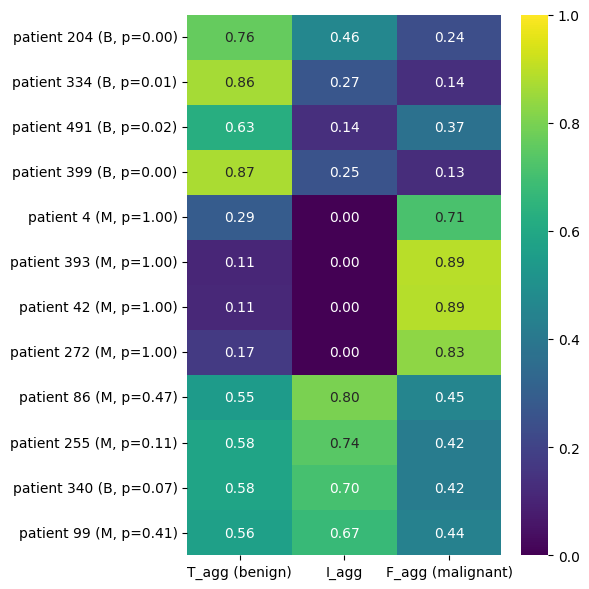

In [18]:
AGG = np.zeros((len(y), 3))
for tr, te in splits[:5]:
    f = build_fold(tr, te); ntr = f['ntr']; b = f['blocks']
    AGG[te, 0], AGG[te, 1], AGG[te, 2] = b['T'][ntr:, 30], b['I'][ntr:, 30], b['F'][ntr:, 30]
import seaborn as sns
p0 = oof['NGNN-MADM'][0]; rng = np.random.default_rng(0)
hi_I = list(np.argsort(-AGG[:, 1])[:4])
ben = list(rng.choice(np.where((y == 0) & (p0 < .1))[0], 4, replace=False))
mal = list(rng.choice(np.where((y == 1) & (p0 > .9))[0], 4, replace=False))
sel = ben + mal + hi_I
lab = [f"patient {i} ({'M' if y[i] else 'B'}, p={p0[i]:.2f})" for i in sel]
plt.figure(figsize=(6, 6)); sns.heatmap(AGG[sel], annot=True, fmt='.2f', vmin=0, vmax=1, cmap='viridis',
    xticklabels=['T_agg (benign)', 'I_agg', 'F_agg (malignant)'], yticklabels=lab); plt.tight_layout()
plt.savefig(f'{OUT}/heatmap_aggregated_triplet.png', dpi=200); plt.show()

In [19]:
print('corr I_final vs I_agg:', np.corrcoef(FIN['I'][0], Iagg[0])[0, 1].round(3))
print(pd.DataFrame({'I_agg': Iagg[0], 'I_final': FIN['I'][0], 'class': y}).groupby('class').agg(['mean', 'std']).round(3))

corr I_final vs I_agg: 0.061
      I_agg        I_final       
       mean    std    mean    std
class                            
0      0.33  0.109   0.207  0.318
1      0.13  0.188   0.209  0.308


In [20]:
# Cell 12: monotone (pooled-variance) membership versus Gaussian (#6)
def reversed_share(pooled):
    out = {}
    for j, c in enumerate(cols):
        a, b = X[y == 0, j], X[y == 1, j]
        sb, sm_ = (np.sqrt(((len(a)-1)*a.var(ddof=1)+(len(b)-1)*b.var(ddof=1))/(len(a)+len(b)-2)),)*2 if pooled else (a.std(), b.std())
        dl = -(X[:, j] - a.mean())/sb**2 + (X[:, j] - b.mean())/sm_**2            # d(llr)/dx
        out[c] = 100 * (np.sign(dl) != (-1 if b.mean() > a.mean() else 1)).mean()
    return pd.Series(out)
rs = pd.DataFrame({'Gaussian (separate sigma)': reversed_share(False), 'Pooled sigma': reversed_share(True)}).round(1)
print('Share of patients on the REVERSED side of T (%), top 8:'); print(rs.sort_values('Gaussian (separate sigma)', ascending=False).head(8))
print('Features with any reversal: Gaussian =', (rs.iloc[:, 0] > 0).sum(), '| pooled =', (rs.iloc[:, 1] > 0).sum())
run_model('RefNGNN-MADM-pooled', lambda tr, te: ref_fit_predict(tr, te, k=10, pooled=True))
run_model('RefNGNN-MADM-priors', lambda tr, te: ref_fit_predict(tr, te, k=10, prior_shift=np.log(357/212)))   # #5 sensitivity

Share of patients on the REVERSED side of T (%), top 8:
                         Gaussian (separate sigma)  Pooled sigma
texture_se                                    55.2           0.0
fractal_dimension_mean                        36.7           0.0
symmetry_se                                   36.4           0.0
area_se                                       34.8           0.0
perimeter_se                                  30.6           0.0
radius_se                                     29.9           0.0
fractal_dimension_se                          26.0           0.0
fractal_dimension_worst                       24.1           0.0
Features with any reversal: Gaussian = 20 | pooled = 0
RefNGNN-MADM-pooled acc 97.47 (SD per fold 1.51)  AUC 0.9938  Brier 0.0211  [7s]
RefNGNN-MADM-priors acc 97.49 (SD per fold 1.49)  AUC 0.9938  Brier 0.0211  [4s]


In [21]:
# Cell 13: LLR control (#4) and alternative patient-level scores (#7, #8, #12)
def control_fit_predict(kind, learner):
    def f(tr, te):
        sc = StandardScaler().fit(X[tr]); Ztr, Zte = sc.transform(X[tr]), sc.transform(X[te]); par = fit_gauss(Ztr, y[tr])
        Ltr, Lte = llr(Ztr, par), llr(Zte, par)
        A, B = {'raw30': (Ztr, Zte), 'LLR30': (Ltr, Lte), 'TIF90': (np.hstack(tif(Ltr)), np.hstack(tif(Lte)))}[kind]
        return learner().fit(A, y[tr]).predict_proba(B)[:, 1]
    return f
for kind in ('raw30', 'LLR30', 'TIF90'):
    run_model(f'LR-{kind}', control_fit_predict(kind, lambda: LogisticRegression(C=1, max_iter=5000)))
    run_model(f'LGBM-{kind}', control_fit_predict(kind, lambda: LGBMClassifier(n_estimators=200, learning_rate=0.05, verbose=-1, random_state=0)))

def score_auc(weights='entropy'):
    out = {k: [] for k in ('S (NWA)', 'weighted mean T', 'H = T - F')}
    for tr, te in splits:
        sc = StandardScaler().fit(X[tr]); Ztr, Zte = sc.transform(X[tr]), sc.transform(X[te]); par = fit_gauss(Ztr, y[tr])
        Ttr, Itr, Ftr = tif(llr(Ztr, par)); Tte, Ite, Fte = tif(llr(Zte, par))
        if weights == 'entropy': w = entropy_weights(Ttr)
        elif weights == 'equal': w = np.ones(X.shape[1]) / X.shape[1]
        elif weights == 'fisher':
            m1, m0 = Ztr[y[tr] == 1].mean(0), Ztr[y[tr] == 0].mean(0); v = Ztr[y[tr] == 1].var(0) + Ztr[y[tr] == 0].var(0); w = (m1 - m0)**2 / v; w /= w.sum()
        S = nwa(Tte, Ite, Fte, w)[3]
        out['S (NWA)'].append(roc_auc_score(y[te], 1 - S)); out['weighted mean T'].append(roc_auc_score(y[te], -(Tte * w).sum(1)))
        out['H = T - F'].append(roc_auc_score(y[te], -((2*Tte - 1) * w).sum(1)))
    return {k: f'{np.mean(v):.3f} +/- {np.std(v):.3f}' for k, v in out.items()}
print(pd.DataFrame({w: score_auc(w) for w in ('entropy', 'equal', 'fisher')}))

LR-raw30       acc 97.89 (SD per fold 1.43)  AUC 0.9948  Brier 0.0200  [3s]
LGBM-raw30     acc 96.48 (SD per fold 1.49)  AUC 0.9922  Brier 0.0291  [29s]
LR-LLR30       acc 96.85 (SD per fold 1.49)  AUC 0.9918  Brier 0.0256  [1s]
LGBM-LLR30     acc 96.54 (SD per fold 1.45)  AUC 0.9913  Brier 0.0291  [16s]
LR-TIF90       acc 97.19 (SD per fold 1.34)  AUC 0.9945  Brier 0.0230  [1s]
LGBM-TIF90     acc 96.03 (SD per fold 1.53)  AUC 0.9916  Brier 0.0319  [48s]
                         entropy            equal           fisher
S (NWA)          0.962 +/- 0.014  0.924 +/- 0.027  0.968 +/- 0.012
weighted mean T  0.989 +/- 0.006  0.988 +/- 0.007  0.987 +/- 0.007
H = T - F        0.989 +/- 0.006  0.988 +/- 0.007  0.987 +/- 0.007


In [22]:
# Cell 14: save everything for the repository / supplement (#2)
fold_df = pd.DataFrame(fold_rows); fold_df.to_csv(f'{OUT}/per_fold_metrics.csv', index=False)
np.savez(f'{OUT}/oof_predictions.npz', Iagg=Iagg, T_final=FIN['T'], I_final=FIN['I'], F_final=FIN['F'], **{k.replace('-', '_').replace(' ', '_'): v for k, v in oof.items()})
import shutil; shutil.make_archive('ngnn_revision_outputs', 'zip', OUT)
print(sorted(os.listdir(OUT)))
try:
    from google.colab import files; files.download('ngnn_revision_outputs.zip')
except Exception: pass

['ablation_paired_tests.csv', 'decision_curve.png', 'folds.npy', 'heatmap_aggregated_triplet.png', 'iagg_vs_confidence.csv', 'oof_predictions.npz', 'per_fold_metrics.csv', 'table1.csv', 'table2.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

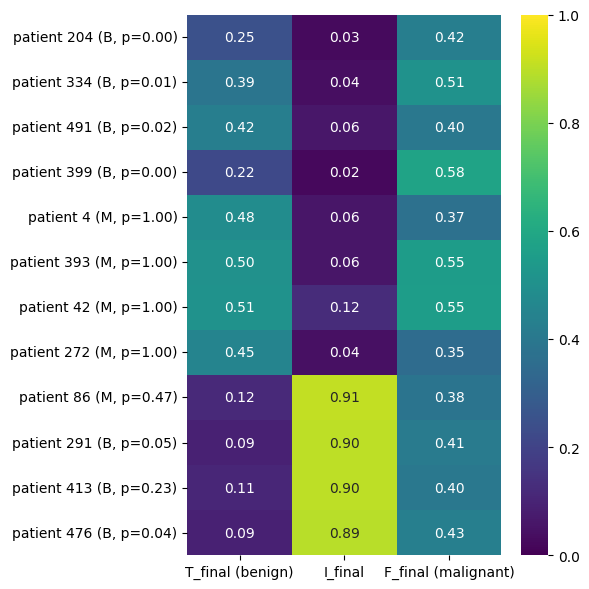

Check: T = benign evidence, F = malignant evidence, as in Section 4.1.


In [23]:
# Cell 15: heatmap of the network output triplet for 12 test patients (#30) - a REAL figure for Section 6.14
import seaborn as sns
p0 = oof['NGNN-MADM'][0]; rng = np.random.default_rng(0)
hi_I = list(np.argsort(-FIN['I'][0])[:4])                                   # most indeterminate
ben  = list(rng.choice(np.where((y == 0) & (p0 < .1))[0], 4, replace=False)) # clear benign
mal  = list(rng.choice(np.where((y == 1) & (p0 > .9))[0], 4, replace=False)) # clear malignant
sel = ben + mal + hi_I
M = np.c_[FIN['T'][0][sel], FIN['I'][0][sel], FIN['F'][0][sel]]
lab = [f"patient {i} ({'M' if y[i] else 'B'}, p={p0[i]:.2f})" for i in sel]
plt.figure(figsize=(6, 6)); sns.heatmap(M, annot=True, fmt='.2f', vmin=0, vmax=1, cmap='viridis',
    xticklabels=['T_final (benign)', 'I_final', 'F_final (malignant)'], yticklabels=lab); plt.tight_layout()
plt.savefig(f'{OUT}/heatmap_triplet.png', dpi=200); plt.show()
print('Check: T = benign evidence, F = malignant evidence, as in Section 4.1.')